In [6]:
from google.colab import files
uploaded = files.upload()

Saving StudentsPerformance.csv to StudentsPerformance (1).csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
import pandas as pd

df = pd.read_csv('StudentsPerformance.csv')

df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [9]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [10]:
df.shape

(1000, 8)

In [11]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [13]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [14]:
df.dtypes

,0
gender,object
race/ethnicity,object
parental level of education,object
lunch,object
test preparation course,object
math score,int64
reading score,int64
writing score,int64


In [15]:
# check for missing value
df.isnull().sum()

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [16]:
#check for duplicate record
df.duplicated().sum()

np.int64(0)

In [17]:
#Remove duplicate records if any
df=df.drop_duplicates()

In [18]:
df.isnull().sum()

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [19]:
df.shape

(1000, 8)

In [20]:
# Feature Engineering
df['total_score']=(df['math score']+df['reading score']+df['writing score'])
df['average_score']=df['total_score']/3
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [21]:
conditions = [
    df['average_score'] >= 80,
    df['average_score'] >= 60,
    df['average_score'] >= 40
]

categories = [
    'Excellent',
    'Good',
    'Average'
]

df['performance']=np.select(conditions,categories,default='Needs Improvement')

In [22]:
df.head(10)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,average_score,performance
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667,Good
1,female,group C,some college,standard,completed,69,90,88,247,82.333333,Excellent
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667,Excellent
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333,Average
4,male,group C,some college,standard,none,76,78,75,229,76.333333,Good
5,female,group B,associate's degree,standard,none,71,83,78,232,77.333333,Good
6,female,group B,some college,standard,completed,88,95,92,275,91.666667,Excellent
7,male,group B,some college,free/reduced,none,40,43,39,122,40.666667,Average
8,male,group D,high school,free/reduced,completed,64,64,67,195,65.000000,Good
9,female,group B,high school,free/reduced,none,38,60,50,148,49.333333,Average


In [23]:
subject_averages = df[
    ['math score', 'reading score', 'writing score']
].mean()

print(subject_averages)

math score       66.089
reading score    69.169
writing score    68.054
dtype: float64


In [24]:
gender_analysis = df.groupby('gender')[
    ['math score', 'reading score', 'writing score']
].mean()

print(gender_analysis)

        math score  reading score  writing score
gender                                          
female   63.633205      72.608108      72.467181
male     68.728216      65.473029      63.311203


In [25]:
test_prep_analysis = df.groupby('test preparation course')[
    ['math score', 'reading score', 'writing score']
].mean()

print(test_prep_analysis)

                         math score  reading score  writing score
test preparation course                                          
completed                 69.695531      73.893855      74.418994
none                      64.077882      66.534268      64.504673


In [26]:
parent_education = df.groupby(
    'parental level of education'
)['average_score'].mean().sort_values(ascending=False)

print(parent_education)

parental level of education
master's degree       73.598870
bachelor's degree     71.923729
associate's degree    69.569069
some college          68.476401
some high school      65.108007
high school           63.096939
Name: average_score, dtype: float64


In [27]:
lunch_analysis = df.groupby('lunch')[
    ['math score', 'reading score', 'writing score']
].mean()

print(lunch_analysis)

              math score  reading score  writing score
lunch                                                 
free/reduced   58.921127      64.653521      63.022535
standard       70.034109      71.654264      70.823256


In [28]:
print(df['performance'].value_counts())

performance
Good                 517
Average              255
Excellent            198
Needs Improvement     30
Name: count, dtype: int64


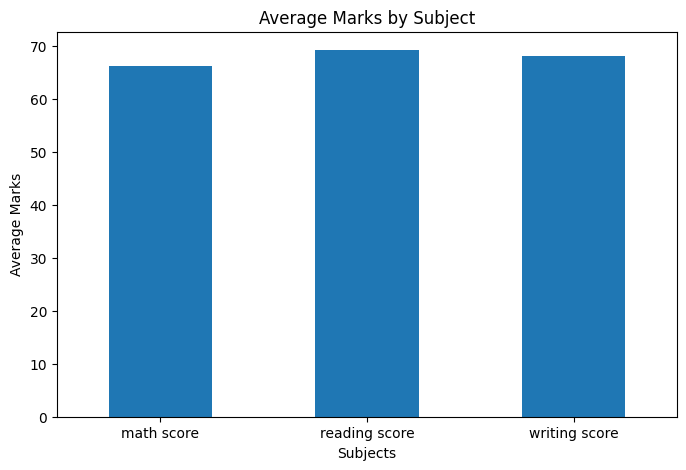

In [29]:
subject_averages.plot(
    kind='bar',
    figsize=(8, 5),
    title='Average Marks by Subject'
)

plt.xlabel('Subjects')
plt.ylabel('Average Marks')
plt.xticks(rotation=0)
plt.show()

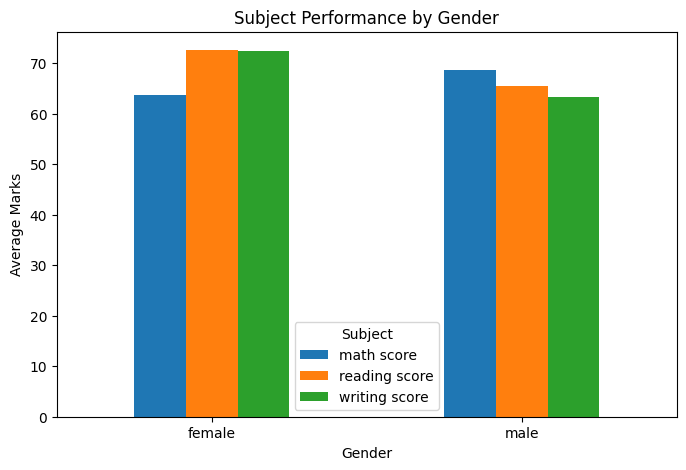

In [30]:
gender_analysis.plot(kind='bar',figsize=(8,5))
plt.title('Subject Performance by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Marks')
plt.xticks(rotation=0)
plt.legend(title='Subject')
plt.show()

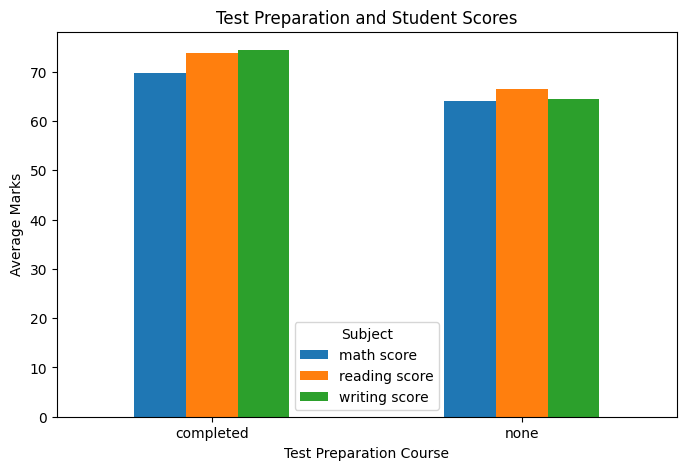

In [31]:
test_prep_analysis.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Test Preparation and Student Scores')
plt.xlabel('Test Preparation Course')
plt.ylabel('Average Marks')
plt.xticks(rotation=0)
plt.legend(title='Subject')
plt.show()

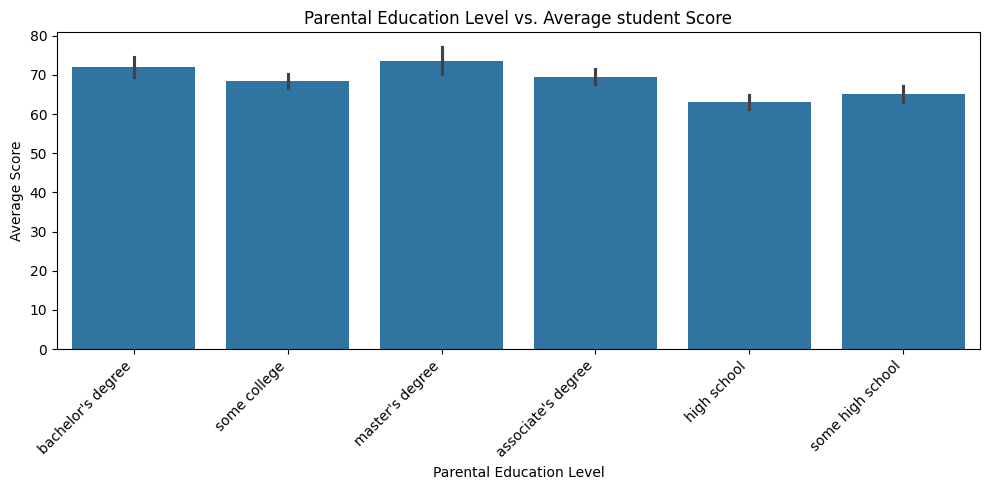

In [32]:
plt.figure(figsize=(10,5))
sns.barplot(
x='parental level of education',
y='average_score',
data=df
)
plt.title('Parental Education Level vs. Average student Score')
plt.xlabel('Parental Education Level')
plt.ylabel('Average Score')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

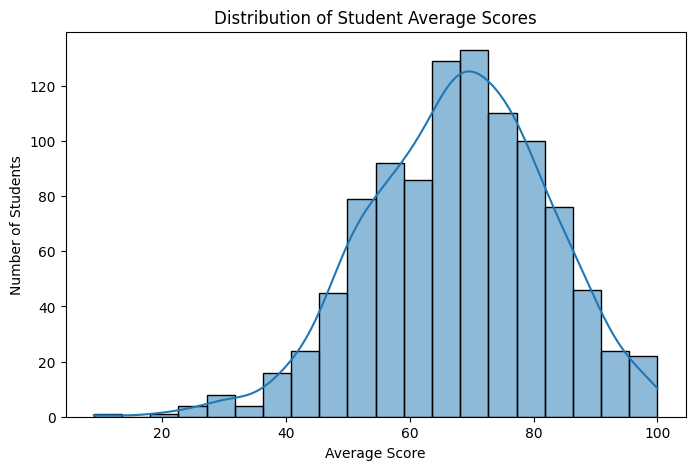

In [33]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['average_score'],
    bins=20,
    kde=True
)

plt.title('Distribution of Student Average Scores')
plt.xlabel('Average Score')
plt.ylabel('Number of Students')
plt.show()

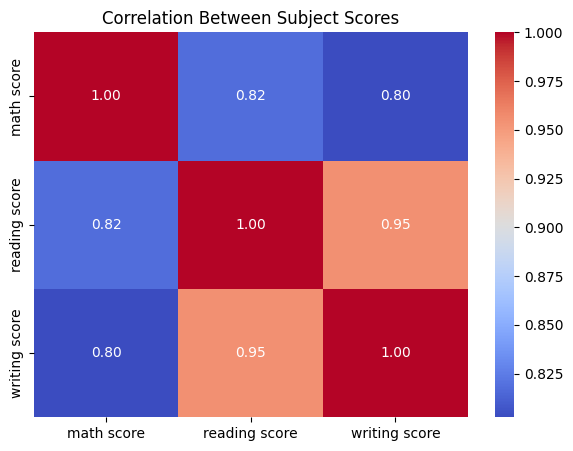

In [34]:
plt.figure(figsize=(7, 5))

correlation = df[
    ['math score', 'reading score', 'writing score']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Subject Scores')
plt.show()

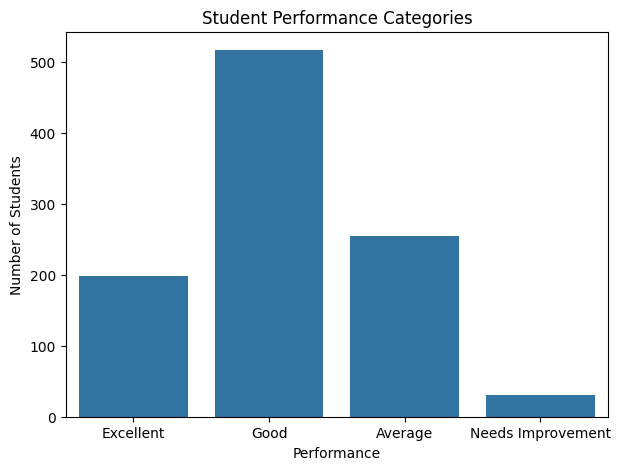

In [35]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='performance',
    order=[
        'Excellent',
        'Good',
        'Average',
        'Needs Improvement'
    ]
)

plt.title('Student Performance Categories')
plt.xlabel('Performance')
plt.ylabel('Number of Students')
plt.show()

In [36]:
low_performance = df[
    df['average_score'] < 40
]

print("Students below the project threshold:")
print(low_performance.head())

Students below the project threshold:
    gender race/ethnicity parental level of education         lunch  \
17  female        group B            some high school  free/reduced   
55  female        group C                 high school  free/reduced   
59  female        group C            some high school  free/reduced   
61    male        group A            some high school  free/reduced   
66    male        group D            some high school  free/reduced   

   test preparation course  math score  reading score  writing score  \
17                    none          18             32             28   
55                    none          33             41             43   
59                    none           0             17             10   
61                    none          39             39             34   
66                    none          45             37             37   

    total_score  average_score        performance  
17           78      26.000000  Needs Improvement 

In [37]:
print("Number of students:", len(low_performance))


Number of students: 30


In [38]:
df.to_csv('Student_Performance_Analyzed.csv', index=False)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [39]:
!pip install streamlit plotly pandas


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 19.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 51.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [40]:
from google.colab import files
uploaded = files.upload()

Saving StudentsPerformance.csv to StudentsPerformance (2).csv


In [41]:
import pandas as pd

df = pd.read_csv("StudentsPerformance.csv")

print(df.shape)
df.head()

(1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [42]:
%%writefile app.py

import streamlit as st
import pandas as pd
import plotly.express as px
import numpy as np

st.set_page_config(
    page_title="Student Performance Dashboard",
    page_icon="🎓",
    layout="wide"
)

df = pd.read_csv("StudentsPerformance.csv")

# Feature engineering
df["total_score"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
)

df["average_score"] = df["total_score"] / 3

conditions = [
    df["average_score"] >= 80,
    df["average_score"] >= 60,
    df["average_score"] >= 40
]

categories = ["Excellent", "Good", "Average"]

df["performance"] = np.select(
    conditions,
    categories,
    default="Needs Improvement"
)

# Dashboard heading
st.title("🎓 Student Performance Analysis")
st.write("Interactive analysis of student academic performance.")

# Sidebar filters
st.sidebar.header("Filters")

selected_gender = st.sidebar.multiselect(
    "Gender",
    df["gender"].unique(),
    default=df["gender"].unique()
)

selected_prep = st.sidebar.multiselect(
    "Test Preparation",
    df["test preparation course"].unique(),
    default=df["test preparation course"].unique()
)

filtered_df = df[
    (df["gender"].isin(selected_gender)) &
    (df["test preparation course"].isin(selected_prep))
]

# KPI metrics
st.subheader("Overall Statistics")

c1, c2, c3, c4 = st.columns(4)

c1.metric("Total Students", len(filtered_df))

c2.metric(
    "Average Score",
    round(filtered_df["average_score"].mean(), 2)
)

c3.metric(
    "Highest Score",
    filtered_df["average_score"].max()
)

c4.metric(
    "Lowest Score",
    filtered_df["average_score"].min()
)

# Subject analysis
st.subheader("Subject Performance")

subject_avg = filtered_df[
    ["math score", "reading score", "writing score"]
].mean().reset_index()

subject_avg.columns = ["Subject", "Average Score"]

fig1 = px.bar(
    subject_avg,
    x="Subject",
    y="Average Score",
    color="Subject",
    title="Average Marks by Subject"
)

st.plotly_chart(fig1, use_container_width=True)

# Performance distribution
st.subheader("Performance Distribution")

fig2 = px.pie(
    filtered_df,
    names="performance",
    hole=0.4,
    title="Student Performance Categories"
)

st.plotly_chart(fig2, use_container_width=True)

# Test preparation analysis
st.subheader("Test Preparation Analysis")

prep_avg = filtered_df.groupby(
    "test preparation course"
)[
    ["math score", "reading score", "writing score"]
].mean().reset_index()

prep_melted = prep_avg.melt(
    id_vars="test preparation course",
    var_name="Subject",
    value_name="Average Score"
)

fig3 = px.bar(
    prep_melted,
    x="test preparation course",
    y="Average Score",
    color="Subject",
    barmode="group"
)

st.plotly_chart(fig3, use_container_width=True)

# Student records
st.subheader("Student Records")

st.dataframe(filtered_df, use_container_width=True)

Writing app.py


In [43]:
!npm install -g localtunnel


⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇
added 22 packages in 3s
⠇
⠇3 packages are looking for funding
⠇  run `npm fund` for details
⠇

In [44]:
!streamlit run app.py &>/content/streamlit.log &

In [45]:
!ls -l

total 444
-rw-r--r-- 1 root root   2864 Nov 18 13:12  app.py
drwxr-xr-x 1 root root   4096 Oct 26 22:18  sample_data
-rw-r--r-- 1 root root      0 Nov 18 13:12  streamlit.log
-rw-r--r-- 1 root root  81027 Nov 18 13:11  Student_Performance_Analyzed.csv
-rw-r--r-- 1 root root  72036 Nov 18 13:11 'StudentsPerformance (1).csv'
-rw-r--r-- 1 root root  72036 Nov 18 13:12 'StudentsPerformance (2).csv'
-rw-r--r-- 1 root root  72036 Nov 18 13:11  StudentsPerformance.csv
-rw-r--r-- 1 root root 140679 Nov 18 13:08  VIX9D_History.csv


In [46]:
!cat /content/streamlit.log

In [47]:
!curl -I http://127.0.0.1:8501

curl: (7) Failed to connect to 127.0.0.1 port 8501 after 1 ms: Couldn't connect to server


In [48]:
!npm install -g localtunnel


⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼
changed 22 packages in 2s
⠼
⠼3 packages are looking for funding
⠼  run `npm fund` for details
⠼

In [ ]:
!lt --port 8501

your url is: https://lovely-hairs-nail.loca.lt
